# Figure 3 — Comparison with cell-cell communication methods

Run **Restart Kernel and Run All Cells**. Every panel is redrawn from checked numerical tables; no saved manuscript image is used as an input. The cells export new PNG/PDF/SVG files and assemble the complete figure.

This notebook follows the manuscript snapshot dated 2026-10-13. [Plotting source](../reproduction/figure3.py) · [Data provenance](../reproduction/manifest.json) · [Reproduction guide](README.md). The original model implementation and frozen selection remain unchanged. Training seeds measure optimization variability, not biological replication.

In [1]:
from pathlib import Path
import os
import sys

# Works from the repository root or notebooks/; an explicit root is optional.
configured = os.environ.get("SPIKE_CODE_ROOT")
REPO_ROOT = Path(configured).expanduser().resolve() if configured else next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "reproduction/manifest.json").is_file()
)
sys.path.insert(0, str(REPO_ROOT))
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
import matplotlib.pyplot as plt
from IPython.display import display
from reproduction.common import audit, read, save, finish, OUTPUT
from reproduction import figure3 as drawing

manifest = audit()
figures = {}


Input audit: PASS (33 numerical tables)
Figure protocol: Released manuscript graph predictions for all seven datasets; matched split-42 State, seeds 41/42/43. Original frozen model selection remains unchanged.


## A. KEGG enrichment

Top-20 LR pairs in PSAPP. Fifteen displayed terms per method are ordered by minimum Source/Target FDR, then name. Gold bold labels mark every displayed Target-side BH-FDR < 0.05 term. Spike Source is the CellNEST source-only network; its Target is the frozen Spike prediction-associated network export.

Numerical input: [`kegg_PSAPP.csv`](../reproduction/tables/kegg_PSAPP.csv).

Source table: kegg_PSAPP.csv (339, 8)


,Term,p,overlap,set_size,n_query,fdr,method,condition
0,Cell adhesion molecules (CAMs),2.403120e-35,17,159,23,7.281455e-33,spatialDM,source
1,Leukocyte transendothelial migration,1.239605e-06,4,114,23,1.878002e-04,spatialDM,source
2,cAMP signaling pathway,1.397989e-05,4,210,23,1.411969e-03,spatialDM,source
3,Gastric acid secretion,1.980687e-05,3,74,23,1.500370e-03,spatialDM,source
4,Neuroactive ligand-receptor interaction,9.991653e-05,4,348,23,6.054942e-03,spatialDM,source


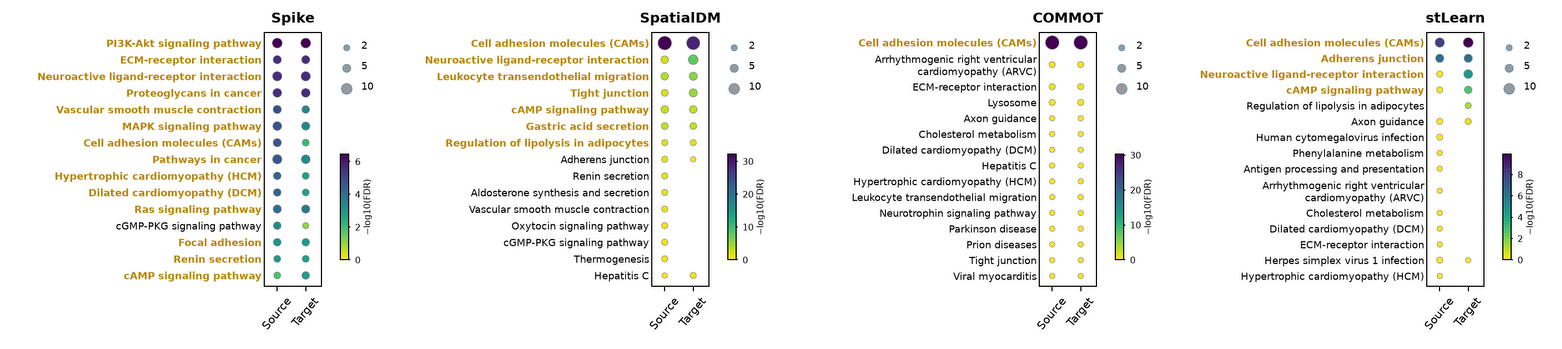

In [2]:
data_a = read('kegg_PSAPP.csv')
print("Source table:", 'kegg_PSAPP.csv', data_a.shape)
display(data_a.head(5))
figures['a'] = drawing.panel_a()
save(figures['a'], 3, 'a')
display(figures['a'])
plt.close(figures['a'])

## B. LR expression changes

Ten largest absolute observed log2 changes within each selected LR set. Red/blue encode direction, ΔM denotes Moran change; stars and diamonds denote the recorded literature annotations. These annotations are descriptive.

Numerical input: [`lr_biological_annotations_PSAPP.csv`](../reproduction/tables/lr_biological_annotations_PSAPP.csv).

Source table: lr_biological_annotations_PSAPP.csv (40, 16)


,method,ligand,receptor,pair,log2fc,abs_log2fc,source_mean,target_mean,delta_moran,celltype_related,mechanism_related,celltype_genes,celltype_context,celltype_sources,mechanism_context,mechanism_sources
0,COMMOT,IGF2,IGF1R,Igf2-Igf1r,0.684235,0.684235,0.165426,0.265814,0.327348,False,False,NaN,NaN,NaN,NaN,NaN
1,COMMOT,PENK,OPRL1,Penk-Oprl1,-0.491970,0.491970,0.488729,0.347512,-0.302022,True,False,PENK,Neuropeptidergic neuron,https://pmc.ncbi.nlm.nih.gov/articles/PMC7615022/,NaN,NaN
2,COMMOT,NECTIN1,NECTIN3,Nectin1-Nectin3,0.339465,0.339465,0.155365,0.196581,0.098846,False,False,NaN,NaN,NaN,NaN,NaN
3,COMMOT,NECTIN3,NECTIN1,Nectin3-Nectin1,0.339465,0.339465,0.155365,0.196581,0.098846,False,False,NaN,NaN,NaN,NaN,NaN
4,COMMOT,CSF1,CSF1R,Csf1-Csf1r,-0.291105,0.291105,0.321744,0.262953,-0.083562,True,False,CSF1R,Microglia / myeloid,https://pmc.ncbi.nlm.nih.gov/articles/PMC4161285/,NaN,NaN


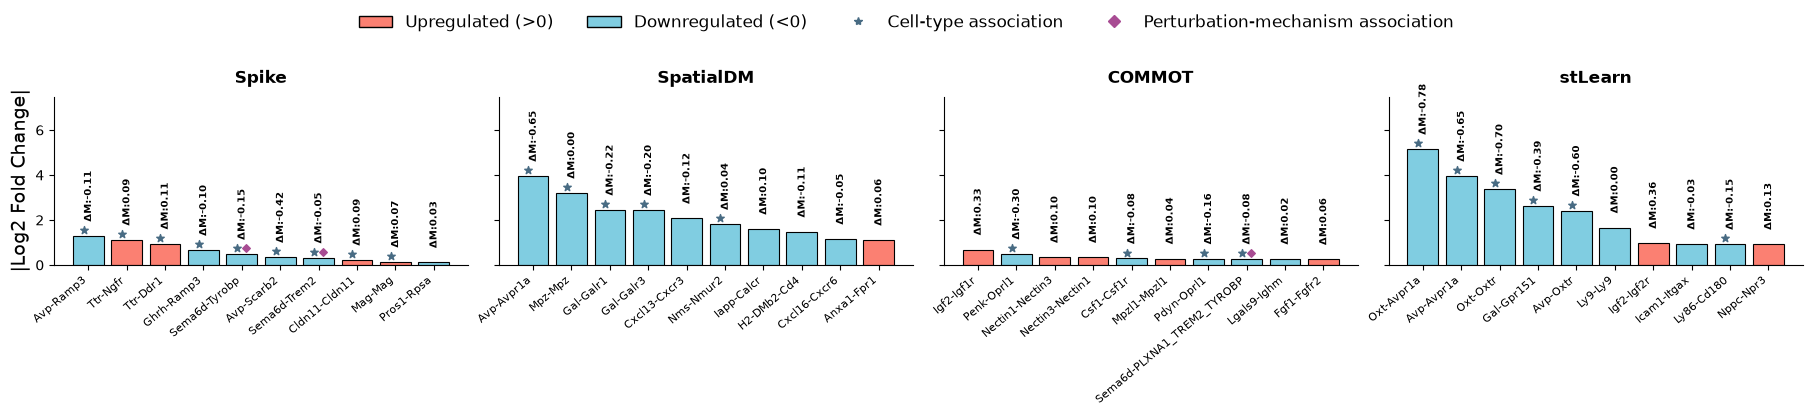

In [3]:
data_b = read('lr_biological_annotations_PSAPP.csv')
print("Source table:", 'lr_biological_annotations_PSAPP.csv', data_b.shape)
display(data_b.head(5))
figures['b'] = drawing.panel_b()
save(figures['b'], 3, 'b')
display(figures['b'])
plt.close(figures['b'])

## C. NCAM1 spatial expression

Observed source section above and target section below, with one shared log1p CPM10k color scale.

Numerical input: [`spatial_spots_PSAPP.csv`](../reproduction/tables/spatial_spots_PSAPP.csv).

Source table: spatial_spots_PSAPP.csv (6244, 22)


,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,log1p_total_counts_mito,pct_counts_mito,clusters,cell_type,drug,spot_id,x,y,expression,cluster
0,1,50,102,7690,8.947806,45898.0,10.734199,25.319186,31.447993,39.886270,...,8.637639,12.285938,3,Neuron,control,AAACAAGTATCTCCCA-1-c,2571,2307,0.736864,5.0
1,1,59,19,4764,8.469053,17535.0,9.772011,32.323924,37.792985,45.155403,...,7.892452,15.260906,14,Pericyte,control,AAACACCAATAACTGC-1-c,748,2651,0.000000,2.0
2,1,43,9,5634,8.636752,19985.0,9.902787,23.052289,29.442082,37.873405,...,7.510430,9.136852,17,Astrocyte,control,AAACAGCTTTCAGAAG-1-c,528,2040,1.705362,3.0
3,1,47,13,6805,8.825560,28799.0,10.268130,19.948609,25.872426,33.567138,...,7.992607,10.271190,0,Astrocyte,control,AAACAGGGTCTATATT-1-c,616,2193,0.527369,2.0
4,1,73,43,3484,8.156223,12646.0,9.445175,43.484106,49.509726,56.761031,...,7.643003,16.487427,6,Astrocyte,control,AAACAGTGTTCCTGGG-1-c,1275,3186,0.000000,3.0


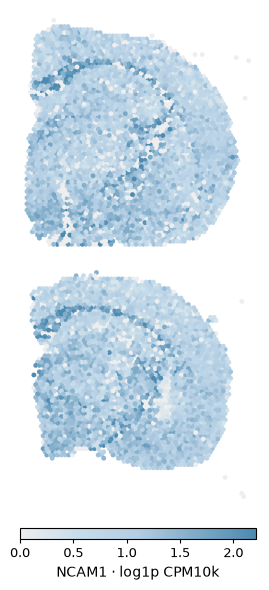

In [4]:
data_c = read('spatial_spots_PSAPP.csv')
print("Source table:", 'spatial_spots_PSAPP.csv', data_c.shape)
display(data_c.head(5))
figures['c'] = drawing.panel_c()
save(figures['c'], 3, 'c')
display(figures['c'])
plt.close(figures['c'])

## D. NCAM1–NCAM1 interaction network

All 302 directed edges are retained. Map and stacked-bar colors use the recorded cell-type annotations. Percentages use all 302 edges, including reciprocal records; outlined spots are connected endpoints.

Numerical input: [`ncam1_celltype_edges_PSAPP.csv`](../reproduction/tables/ncam1_celltype_edges_PSAPP.csv).

Source table: ncam1_celltype_edges_PSAPP.csv (302, 10)


,source_id,target_id,lr_id,attention,ligand,receptor,sender_cluster,receiver_cluster,sender_type,receiver_type
0,AAACTGCTGGCTCCAA-1-c,AAATACCTATAAGCAT-1-c,667,0.008197,NCAM1,NCAM1,4.0,4.0,Oligodendrocyte,Oligodendrocyte
1,AAACTGCTGGCTCCAA-1-c,ACTTGACTCCCTCTTT-1-c,667,0.009551,NCAM1,NCAM1,4.0,4.0,Oligodendrocyte,Oligodendrocyte
2,AAACTGCTGGCTCCAA-1-c,CTAGATTTACGACGGC-1-c,667,0.002967,NCAM1,NCAM1,4.0,4.0,Oligodendrocyte,Oligodendrocyte
3,AAACTGCTGGCTCCAA-1-c,TGGCAGATTACGATCA-1-c,667,0.009937,NCAM1,NCAM1,4.0,4.0,Oligodendrocyte,Oligodendrocyte
4,AAAGTCGACCCTCAGT-1-c,CCAGCTGATGGTACTT-1-c,667,0.016159,NCAM1,NCAM1,3.0,3.0,Astrocyte,Neuron


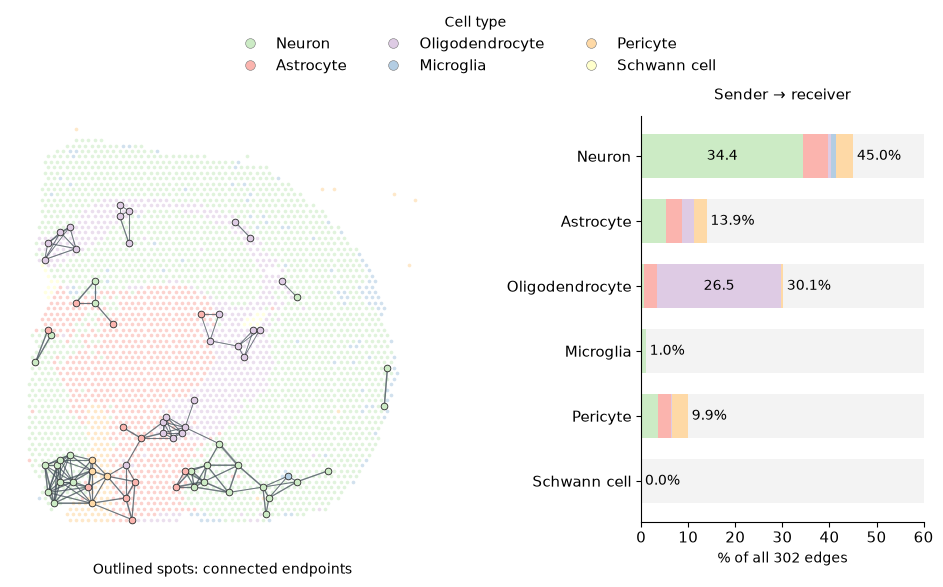

In [5]:
data_d = read('ncam1_celltype_edges_PSAPP.csv')
print("Source table:", 'ncam1_celltype_edges_PSAPP.csv', data_d.shape)
display(data_d.head(5))
figures['d'] = drawing.panel_d()
save(figures['d'], 3, 'd')
display(figures['d'])
plt.close(figures['d'])

## E. Catalogue enrichment against the candidate pool

OmniPath support fraction among top-20 LR pairs divided by the fraction in each method’s full eligible scored pool. Pool sizes are printed below the method labels.

Numerical input: [`catalog_top20_hits_PSAPP.csv`](../reproduction/tables/catalog_top20_hits_PSAPP.csv).

Source table: catalog_top20_hits_PSAPP.csv (8, 11)


,method,catalog,pool_n,pool_hits,pool_fraction,eligible,hits,precision,lift_over_pool,null_rate,enrichment_over_null
0,spike,CellChat,115,21,0.182609,20,4,0.20,1.095238,0.015873,12.600000
1,spike,OmniPath,115,15,0.130435,20,6,0.30,2.300000,0.023810,12.600000
2,spatialDM,CellChat,201,200,0.995025,20,20,1.00,1.005000,0.084795,11.793103
3,spatialDM,OmniPath,201,83,0.412935,20,9,0.45,1.089759,0.038012,11.838462
4,COMMOT,CellChat,102,102,1.000000,20,20,1.00,1.000000,0.072368,13.818182


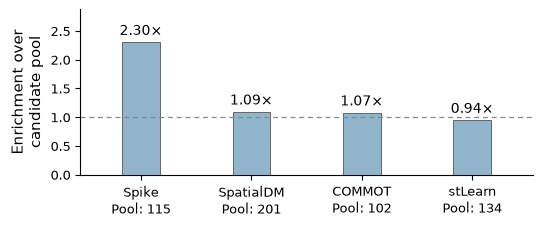

In [6]:
data_e = read('catalog_top20_hits_PSAPP.csv')
print("Source table:", 'catalog_top20_hits_PSAPP.csv', data_e.shape)
display(data_e.head(5))
figures['e'] = drawing.panel_e()
save(figures['e'], 3, 'e')
display(figures['e'])
plt.close(figures['e'])

## F. Catalogue enrichment against the L×R null

OmniPath and CellChat support relative to all ligand–receptor combinations from each method’s selected vocabulary. Bars within each method touch. E and F use distinct denominators; shared catalogue priors prevent interpreting this as independent biological validation.

Numerical input: [`catalog_top20_hits_PSAPP.csv`](../reproduction/tables/catalog_top20_hits_PSAPP.csv).

Source table: catalog_top20_hits_PSAPP.csv (8, 11)


,method,catalog,pool_n,pool_hits,pool_fraction,eligible,hits,precision,lift_over_pool,null_rate,enrichment_over_null
0,spike,CellChat,115,21,0.182609,20,4,0.20,1.095238,0.015873,12.600000
1,spike,OmniPath,115,15,0.130435,20,6,0.30,2.300000,0.023810,12.600000
2,spatialDM,CellChat,201,200,0.995025,20,20,1.00,1.005000,0.084795,11.793103
3,spatialDM,OmniPath,201,83,0.412935,20,9,0.45,1.089759,0.038012,11.838462
4,COMMOT,CellChat,102,102,1.000000,20,20,1.00,1.000000,0.072368,13.818182


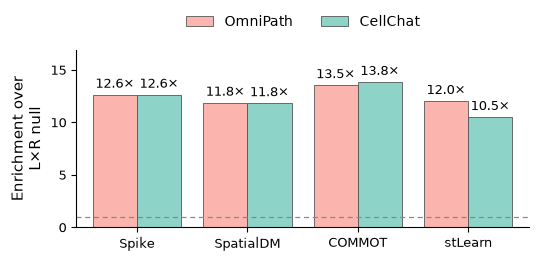

In [7]:
data_f = read('catalog_top20_hits_PSAPP.csv')
print("Source table:", 'catalog_top20_hits_PSAPP.csv', data_f.shape)
display(data_f.head(5))
figures['f'] = drawing.panel_f()
save(figures['f'], 3, 'f')
display(figures['f'])
plt.close(figures['f'])

## Complete figure and output verification

The composite uses only the figures generated above, assembled in memory. It writes `complete.png`, `complete.pdf`, `complete.svg` and a validation record.

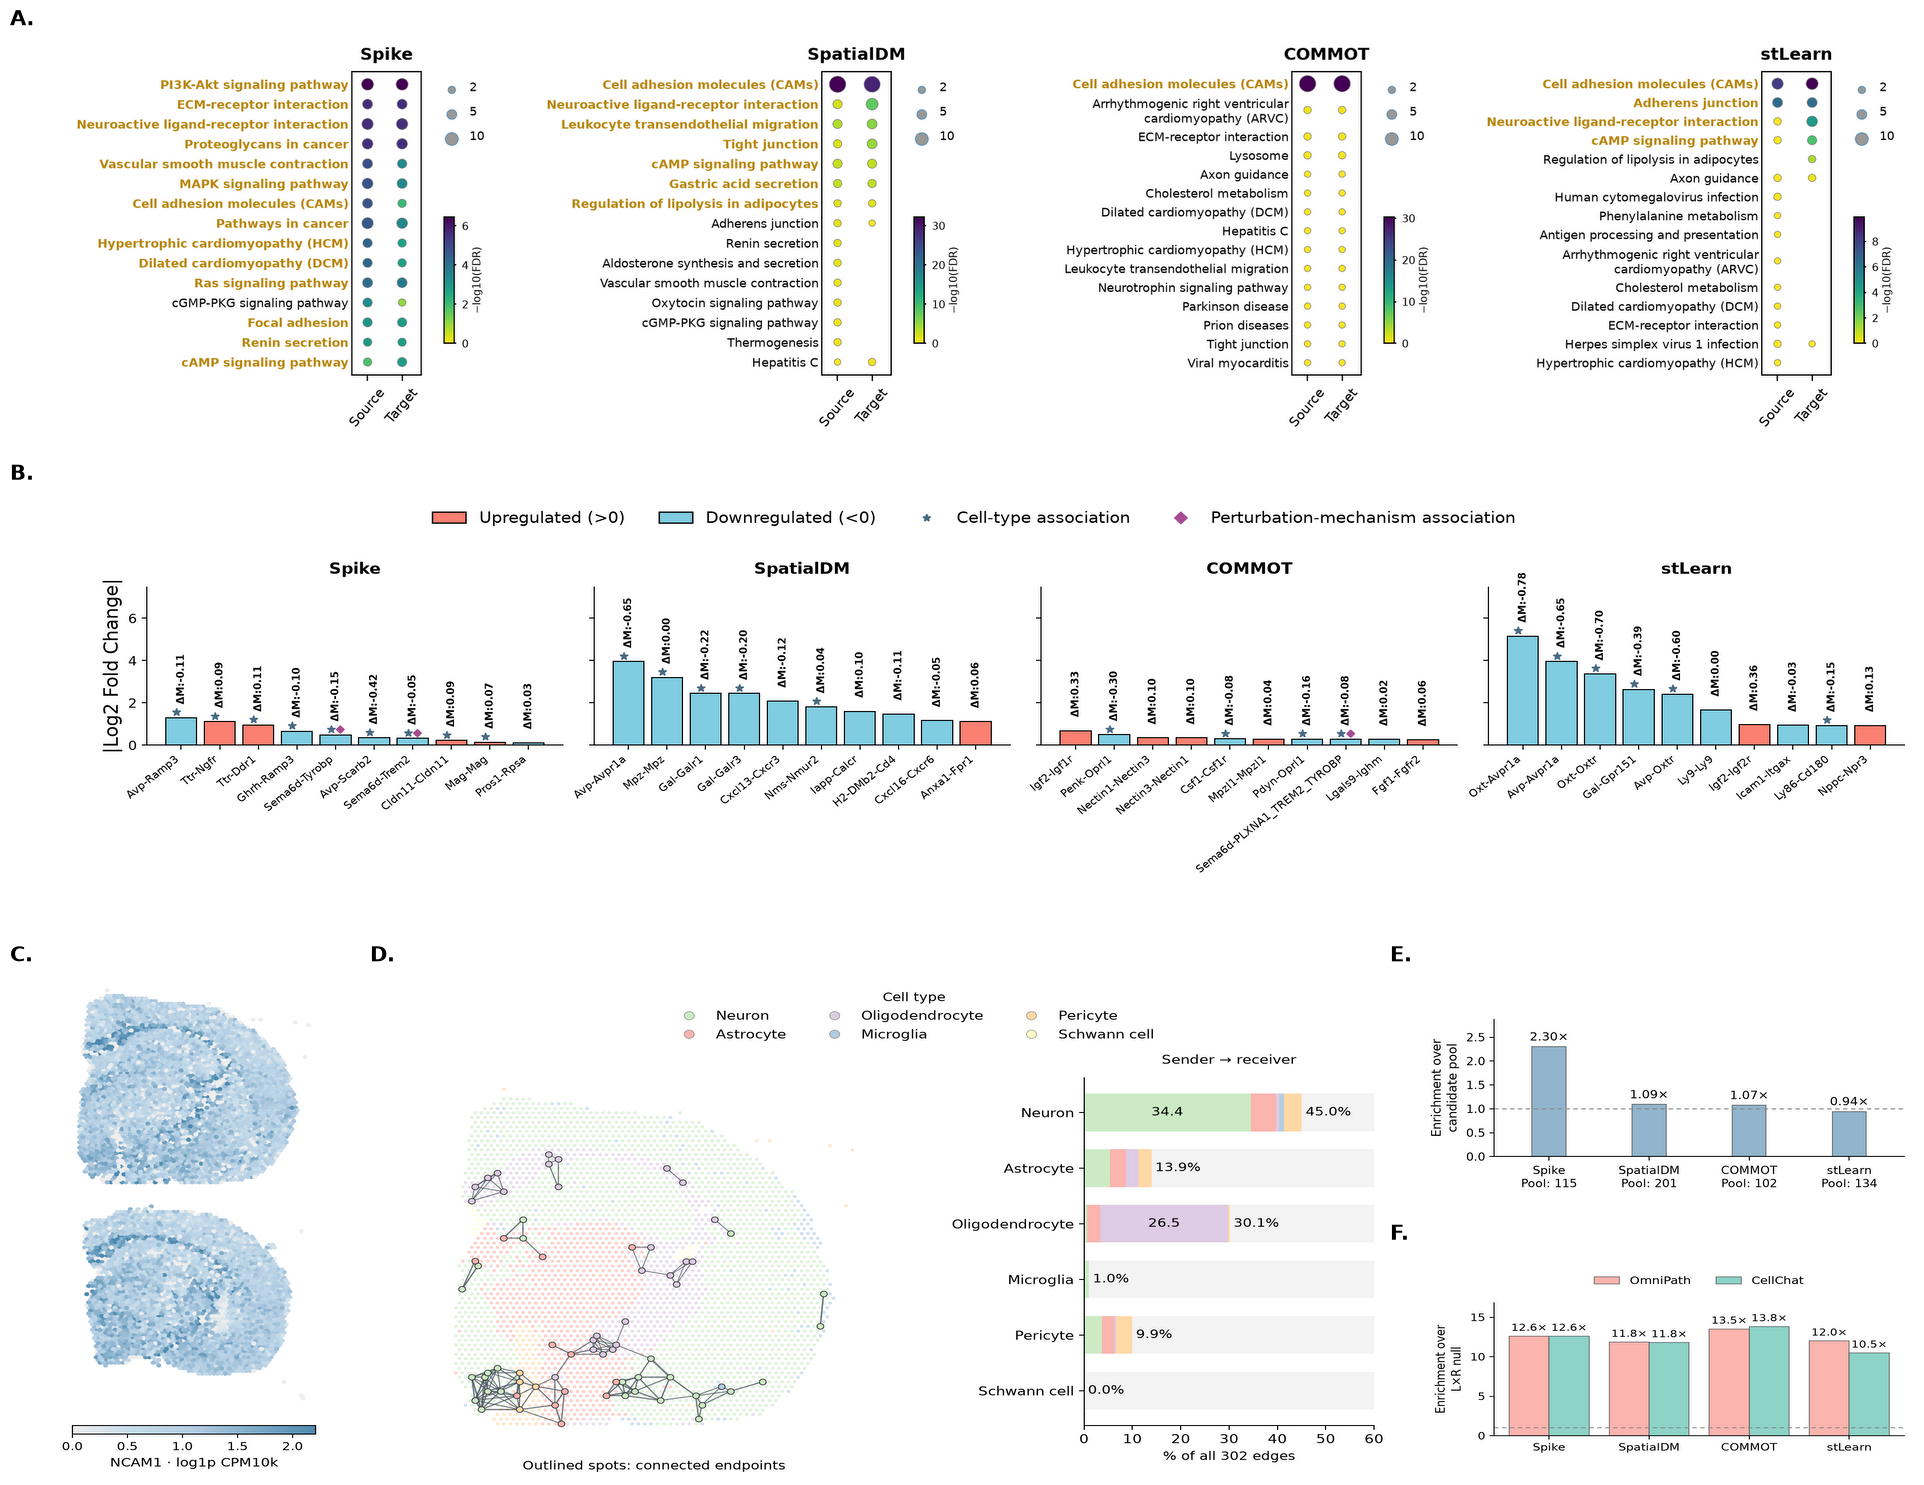

Figure 3: PASS — 6 panels redrawn from numerical tables
Outputs: /Users/jasmine/Documents/GitHub/spike/outputs/reproduction/figure3


In [8]:
complete = drawing.complete(figures)
save(complete, 3, "complete")
display(complete)
plt.close(complete)
report = finish(3, drawing.PANELS)